# Project 3: Building the Best Name Gender Classifier

**Joao De Oliveira** · DATA 620

## Assignment
Using any of the three classifiers described in Chapter 6 of *Natural Language Processing with Python*, and any features we can think of, build the best name gender classifier we can:
1. Split the Names Corpus into a **test set** (500 names), a **dev-test set** (500 names) and a **training set** (the rest).
2. Start with the book's example name gender classifier and make **incremental improvements**, using the dev-test set to check progress.
3. Try **multiple features and feature combinations**. Classifiers from scikit-learn are allowed.
4. Check the final classifier's performance on the test set. How does it compare with the dev-test set? Is this what we'd expect?

In [14]:
import random, itertools, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.download('names', quiet=True)
from nltk.corpus import names

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore')
BLUE, GRAY = '#2a78d6', '#9a9893'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True})

## 1. Splitting the Names Corpus
I label every name, shuffle once with a fixed seed (so the results are reproducible), and split:
- `test_names`: the first 500 names, **not used until the final evaluation**
- `devtest_names`: the next 500 names, used to check every improvement
- `train_names`: everything else

The corpus has 7,944 names, so the training set has 6,944 (the assignment's "6,900" is approximate).

In [15]:
male, female = names.words('male.txt'), names.words('female.txt')
labeled_names = [(n, 'male') for n in male] + [(n, 'female') for n in female]

random.seed(620)
random.shuffle(labeled_names)

test_names    = labeled_names[:500]
devtest_names = labeled_names[500:1000]
train_names   = labeled_names[1000:]

print(f"Total names: {len(labeled_names):,}  (male {len(male):,}, female {len(female):,})")
print(f"Train: {len(train_names):,} | Dev-test: {len(devtest_names)} | Test: {len(test_names)}")

# Some names appear in both lists; one of the two copies will always be misclassified
ambiguous = set(male) & set(female)
print(f"\nNames in both lists: {len(ambiguous)} (e.g. {', '.join(sorted(ambiguous)[:8])})")
print(f"Ambiguous names in dev-test: {sum(n in ambiguous for n, _ in devtest_names)}, "
      f"in test: {sum(n in ambiguous for n, _ in test_names)}")

Total names: 7,944  (male 2,943, female 5,001)
Train: 6,944 | Dev-test: 500 | Test: 500

Names in both lists: 365 (e.g. Abbey, Abbie, Abby, Addie, Adrian, Adrien, Ajay, Alex)
Ambiguous names in dev-test: 55, in test: 47


## 2. The book's example classifier
Naive Bayes on the last letter of the name.

In [16]:
def last_letter(name):
    return {'last_letter': name[-1].lower()}

def nb_devtest(extractor):
    # Train NLTK naive Bayes on the training set and score it on the dev-test set
    train_set = [(extractor(n), g) for n, g in train_names]
    dev_set   = [(extractor(n), g) for n, g in devtest_names]
    clf = nltk.NaiveBayesClassifier.train(train_set)
    return clf, nltk.classify.accuracy(clf, dev_set)

base_clf, base_acc = nb_devtest(last_letter)
print(f"Book example (NB, last letter): dev-test accuracy {base_acc:.1%}\n")
base_clf.show_most_informative_features(8)

Book example (NB, last letter): dev-test accuracy 76.0%

Most Informative Features
             last_letter = 'a'            female : male   =     34.6 : 1.0
             last_letter = 'f'              male : female =     28.5 : 1.0
             last_letter = 'k'              male : female =     28.0 : 1.0
             last_letter = 'v'              male : female =     16.2 : 1.0
             last_letter = 'p'              male : female =     15.1 : 1.0
             last_letter = 'd'              male : female =      9.4 : 1.0
             last_letter = 'o'              male : female =      8.8 : 1.0
             last_letter = 'm'              male : female =      8.4 : 1.0


### Error analysis
As in the book, I list the dev-test names the classifier gets wrong and look for patterns.

In [17]:
def get_errors(clf, extractor):
    return [(g, clf.classify(extractor(n)), n) for n, g in devtest_names
            if clf.classify(extractor(n)) != g]

errors = get_errors(base_clf, last_letter)
print(f"{len(errors)} errors out of {len(devtest_names)}")
print("Errors by last letter:", Counter(n[-1].lower() for _, _, n in errors).most_common(8), "\n")
for correct in ['female', 'male']:
    print(f"Actually {correct}: {', '.join(sorted(n for g, _, n in errors if g == correct)[:20])}")

120 errors out of 500
Errors by last letter: [('n', 36), ('e', 25), ('y', 14), ('l', 12), ('h', 7), ('s', 5), ('t', 5), ('o', 4)] 

Actually female: Abigael, Ardelis, Arlyn, Austin, Bird, Birgit, Cameo, Carin, Carleen, Carlyn, Caron, Caryl, Cathleen, Cloris, Coleen, Colleen, Corliss, Cybal, Cybill, Debor
Actually male: Abbie, Andre, Archy, Bartholemy, Bealle, Blaine, Burnaby, Chrissy, Cy, Dewey, Dmitri, Emile, Felipe, Franky, Friedrich, George, Georgia, Haleigh, Haley, Hersch


The errors concentrate on names ending in **n, e and y**, where one letter isn't enough. Longer endings separate them (*-lyn, -een, -ine* are female, *-son, -ton* lean male), and some patterns are at the start of the name. So the improvements add, one at a time:

| Group | Features |
|---|---|
| suffixes | last 1, 2, 3 and 4 letters |
| prefixes | first 1, 2 and 3 letters |
| shape | length, ends in a vowel, number of vowels |
| letters | count of each letter and whether it appears (the book's "kitchen sink" example) |
| ngrams | every 2- and 3-letter chunk, with `^`/`$` marking the start and end |

## 3. Incremental improvements
Each step adds one idea to the previous step and is checked on the dev-test set.

In [18]:
VOWELS = set('aeiouy')

def suffixes(name, k=4):
    n = name.lower()
    return {f'suffix{i}': n[-i:] for i in range(1, k + 1)}

def prefixes(name, k=3):
    n = name.lower()
    return {f'prefix{i}': n[:i] for i in range(1, k + 1)}

def shape(name):
    n = name.lower()
    return {'length': min(len(n), 10),
            'ends_vowel': n[-1] in VOWELS,
            'n_vowels': min(sum(c in VOWELS for c in n), 5)}

def letters(name):
    n = name.lower()
    f = {}
    for c in 'abcdefghijklmnopqrstuvwxyz':
        f[f'count({c})'] = n.count(c)
        f[f'has({c})'] = c in n
    return f

def ngrams(name):
    n = '^' + name.lower() + '$'
    return {f'ng({n[i:i+k]})': True for k in (2, 3) for i in range(len(n) - k + 1)}

GROUPS = {'suffixes': suffixes, 'prefixes': prefixes, 'shape': shape,
          'letters': letters, 'ngrams': ngrams}

def combine(*group_names):
    # A single extractor that merges several feature groups
    def extractor(name):
        f = {}
        for g in group_names:
            f.update(GROUPS[g](name))
        return f
    return extractor

steps = [
    ('0. Last letter (book)',             last_letter),
    ('1. + 2-letter suffix (book)',       lambda n: suffixes(n, 2)),
    ('2. + 3-letter suffix',              lambda n: suffixes(n, 3)),
    ('3. + 4-letter suffix',              lambda n: suffixes(n, 4)),
    ('4. + prefixes',                     combine('suffixes', 'prefixes')),
    ('5. + shape',                        combine('suffixes', 'prefixes', 'shape')),
    ('6. + letter counts (kitchen sink)', combine('suffixes', 'prefixes', 'shape', 'letters')),
    ('7. letter counts -> n-grams',       combine('suffixes', 'prefixes', 'shape', 'ngrams')),
]
step_df = pd.DataFrame([{'step': label, 'dev_test': nb_devtest(fx)[1]} for label, fx in steps])
step_df['change'] = step_df['dev_test'].diff()
step_df.style.format({'dev_test': '{:.1%}', 'change': '{:+.1%}'}, na_rep='').hide(axis='index')

step,dev_test,change
0. Last letter (book),76.0%,
1. + 2-letter suffix (book),78.2%,+2.2%
2. + 3-letter suffix,79.2%,+1.0%
3. + 4-letter suffix,78.6%,-0.6%
4. + prefixes,85.8%,+7.2%
5. + shape,83.4%,-2.4%
6. + letter counts (kitchen sink),83.8%,+0.4%
7. letter counts -> n-grams,84.8%,+1.0%


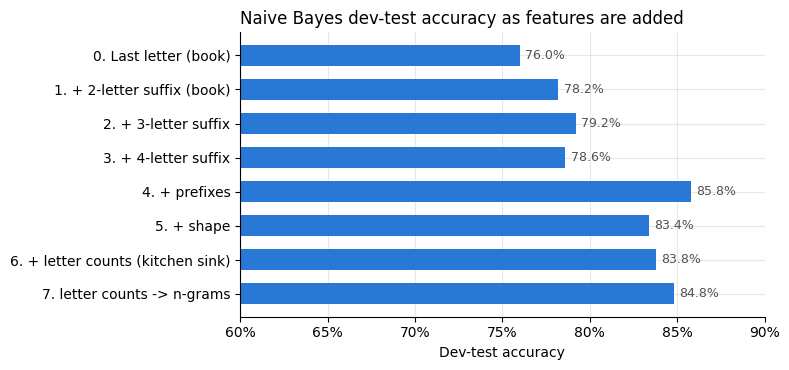

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(step_df))[::-1]
ax.barh(y, step_df['dev_test'], height=0.6, color=BLUE)
for yi, v in zip(y, step_df['dev_test']):
    ax.text(v + 0.003, yi, f'{v:.1%}', va='center', fontsize=9, color='#52514e')
ax.set_yticks(y); ax.set_yticklabels(step_df['step'])
ax.set_xlim(0.6, 0.9); ax.set_xlabel('Dev-test accuracy')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Naive Bayes dev-test accuracy as features are added', loc='left')
plt.tight_layout(); plt.show()

### Error analysis after the improvements

In [20]:
best_step = step_df.loc[step_df['dev_test'].idxmax(), 'step']
best_fx = dict(steps)[best_step]
nb_best, _ = nb_devtest(best_fx)
errors2 = get_errors(nb_best, best_fx)
n_amb = sum(n in ambiguous for _, _, n in errors2)
print(f"Best step: {best_step} -> {len(errors2)} errors (the book example had {len(errors)})")
print(f"{n_amb} of these errors ({n_amb/len(errors2):.0%}) are names that appear in both lists\n")
for correct in ['female', 'male']:
    print(f"Actually {correct} (not ambiguous): "
          f"{', '.join(sorted(n for g, _, n in errors2 if g == correct and n not in ambiguous)[:20])}")

Best step: 4. + prefixes -> 71 errors (the book example had 120)
37 of these errors (52%) are names that appear in both lists

Actually female (not ambiguous): Barbe, Barby, Bird, Birgit, Cameo, Caron, Clemmy, Cybill, Debor, Eden, Harriet, Kipp, Magdalen, Manon, Michell, Milicent, Nike, Phillis, Piper, Rosario
Actually male (not ambiguous): Andre, Bealle, Blaine, Emile, Jessee, Oral, Partha, Penn, Rabi, Tremayne


## 4. Feature combinations
The order in Section 3 is only one path. Here I test every combination of the five feature groups (31 in all) with NLTK naive Bayes and with scikit-learn logistic regression (the same model as the book's maximum entropy classifier, but much faster to train).

In [21]:
def to_xy(extractor, data, vec=None):
    feats = [extractor(n) for n, _ in data]
    y = np.array([g for _, g in data])
    if vec is None:
        vec = DictVectorizer()
        return vec.fit_transform(feats), y, vec
    return vec.transform(feats), y, vec

def sk_devtest(model, extractor):
    X, y, vec = to_xy(extractor, train_names)
    Xd, yd, _ = to_xy(extractor, devtest_names, vec)
    model.fit(X, y)
    return (model.predict(Xd) == yd).mean()

group_names = list(GROUPS)
rows = []
for r in range(1, len(group_names) + 1):
    for combo in itertools.combinations(group_names, r):
        fx = combine(*combo)
        rows.append({'features': ' + '.join(combo), **{g: g in combo for g in group_names},
                     'naive_bayes': nb_devtest(fx)[1],
                     'logistic_regression': sk_devtest(LogisticRegression(max_iter=3000), fx)})
combo_df = pd.DataFrame(rows)
fmt = {'naive_bayes': '{:.1%}', 'logistic_regression': '{:.1%}'}
for col in ['naive_bayes', 'logistic_regression']:
    print(f"Top 5 combinations for {col.replace('_', ' ')} (dev-test accuracy):")
    display(combo_df.sort_values(col, ascending=False)[['features', 'naive_bayes', 'logistic_regression']]
            .head(5).style.format(fmt).hide(axis='index'))

Top 5 combinations for naive bayes (dev-test accuracy):


features,naive_bayes,logistic_regression
suffixes + prefixes,85.8%,85.8%
prefixes + shape + ngrams,85.8%,86.2%
suffixes + prefixes + ngrams,85.0%,85.0%
suffixes + prefixes + shape + letters + ngrams,85.0%,85.0%
suffixes + prefixes + shape + ngrams,84.8%,85.0%


Top 5 combinations for logistic regression (dev-test accuracy):


features,naive_bayes,logistic_regression
prefixes + letters + ngrams,83.0%,86.4%
prefixes + shape + ngrams,85.8%,86.2%
letters + ngrams,83.6%,86.2%
prefixes + shape + letters + ngrams,83.8%,86.2%
shape + letters + ngrams,83.0%,86.2%


**Which groups help?** For each group, I compare the average dev-test accuracy of the combinations that include it with the ones that don't.

In [22]:
effect_df = pd.DataFrame({col: {g: combo_df.loc[combo_df[g], col].mean() - combo_df.loc[~combo_df[g], col].mean()
                                for g in group_names}
                          for col in ['naive_bayes', 'logistic_regression']})
effect_df.style.format('{:+.1%}')

,naive_bayes,logistic_regression
suffixes,+3.6%,+2.8%
prefixes,+1.5%,+1.1%
shape,+0.7%,+0.1%
letters,-0.4%,+0.4%
ngrams,+5.7%,+5.2%


## 5. The three Chapter 6 classifiers
I compare naive Bayes, decision tree and maximum entropy on three feature sets: the book's 2-letter suffixes, suffixes + prefixes, and the best combination for each model from Section 4. Each classifier is run in NLTK and in scikit-learn (`MultinomialNB`, `DecisionTreeClassifier`, `LogisticRegression`).

In [23]:
best_nb_combo = combo_df.sort_values('naive_bayes', ascending=False).iloc[0]['features']
best_lr_combo = combo_df.sort_values('logistic_regression', ascending=False).iloc[0]['features']
feature_sets = {'2-letter suffix (book)': lambda n: suffixes(n, 2),
                'suffixes + prefixes': combine('suffixes', 'prefixes')}
for combo in dict.fromkeys([best_nb_combo, best_lr_combo]):
    feature_sets[combo] = combine(*combo.split(' + '))

nltk_trainers = {
    'Naive Bayes':   nltk.NaiveBayesClassifier.train,
    'Decision tree': nltk.DecisionTreeClassifier.train,
    'MaxEnt':        lambda ts: nltk.MaxentClassifier.train(ts, algorithm='gis', max_iter=30, trace=0),
}
sk_models = {
    'Naive Bayes':   lambda: MultinomialNB(),
    'Decision tree': lambda: DecisionTreeClassifier(random_state=0),
    'MaxEnt':        lambda: LogisticRegression(max_iter=3000),
}

def nltk_devtest(trainer, extractor):
    train_set = [(extractor(n), g) for n, g in train_names]
    dev_set   = [(extractor(n), g) for n, g in devtest_names]
    return nltk.classify.accuracy(trainer(train_set), dev_set)

clf_rows = []
for fs_name, fx in feature_sets.items():
    for model_name in nltk_trainers:
        clf_rows.append({'features': fs_name, 'classifier': model_name,
                         'NLTK': nltk_devtest(nltk_trainers[model_name], fx),
                         'scikit-learn': sk_devtest(sk_models[model_name](), fx)})
clf_df = pd.DataFrame(clf_rows)
clf_df.style.format({'NLTK': '{:.1%}', 'scikit-learn': '{:.1%}'}).hide(axis='index')

features,classifier,NLTK,scikit-learn
2-letter suffix (book),Naive Bayes,78.2%,78.2%
2-letter suffix (book),Decision tree,79.8%,79.8%
2-letter suffix (book),MaxEnt,80.4%,80.4%
suffixes + prefixes,Naive Bayes,85.8%,84.8%
suffixes + prefixes,Decision tree,66.2%,79.4%
suffixes + prefixes,MaxEnt,83.2%,85.8%
prefixes + letters + ngrams,Naive Bayes,83.0%,83.8%
prefixes + letters + ngrams,Decision tree,70.6%,75.0%
prefixes + letters + ngrams,MaxEnt,66.2%,86.4%


### Choosing the final classifier
I keep the classifier with the highest dev-test accuracy in the table above.

In [24]:
long = clf_df.melt(id_vars=['features', 'classifier'], var_name='library', value_name='dev_test')
final = long.sort_values('dev_test', ascending=False, kind='stable').iloc[0]
print(f"Final classifier: {final['classifier']} ({final['library']}) on {final['features']}")
print(f"Dev-test accuracy: {final['dev_test']:.1%}  (book example: {base_acc:.1%}, "
      f"improvement {final['dev_test'] - base_acc:+.1%})")

Final classifier: MaxEnt (scikit-learn) on prefixes + letters + ngrams
Dev-test accuracy: 86.4%  (book example: 76.0%, improvement +10.4%)


## 6. Final evaluation on the test set
The test set is used **once**, with the final classifier trained on the training set.

In [25]:
fx = feature_sets[final['features']]

if final['library'] == 'NLTK':
    model = nltk_trainers[final['classifier']]([(fx(n), g) for n, g in train_names])
    predict = lambda data: np.array([model.classify(fx(n)) for n, _ in data])
else:
    X, y, vec = to_xy(fx, train_names)
    model = sk_models[final['classifier']]().fit(X, y)
    predict = lambda data: model.predict(to_xy(fx, data, vec)[0])

def accuracy(data):
    return (predict(data) == np.array([g for _, g in data])).mean()

dev_final, test_final = accuracy(devtest_names), accuracy(test_names)
base_test = nltk.classify.accuracy(base_clf, [(last_letter(n), g) for n, g in test_names])

summary = pd.DataFrame({'Dev-test': [base_acc, dev_final], 'Test': [base_test, test_final]},
                       index=['Book example (NB, last letter)', 'Final classifier'])
summary['Test - Dev-test'] = summary['Test'] - summary['Dev-test']
display(summary.style.format('{:.1%}').format('{:+.1%}', subset=['Test - Dev-test']))

# how precise is an accuracy measured on 500 names
se = np.sqrt(test_final * (1 - test_final) / 500)
print(f"Standard error of a 500-name accuracy: about {se:.1%}")
print(f"95% interval for the test accuracy: {test_final - 1.96*se:.1%} to {test_final + 1.96*se:.1%}")

,Dev-test,Test,Test - Dev-test
"Book example (NB, last letter)",76.0%,75.4%,-0.6%
Final classifier,86.4%,83.6%,-2.8%


Standard error of a 500-name accuracy: about 1.7%
95% interval for the test accuracy: 80.4% to 86.8%


In [26]:
# What does the final classifier get wrong on the test set?
test_pred = predict(test_names)
test_errors = [(g, p, n) for (n, g), p in zip(test_names, test_pred) if g != p]
n_amb = sum(n in ambiguous for _, _, n in test_errors)
print(f"Test errors: {len(test_errors)} ({n_amb} are names that appear in both lists)\n")
for correct in ['female', 'male']:
    print(f"Actually {correct} (not ambiguous): "
          f"{', '.join(sorted(n for g, _, n in test_errors if g == correct and n not in ambiguous)[:20])}")

Test errors: 82 (32 are names that appear in both lists)

Actually female (not ambiguous): Abbe, Adriaens, Allyson, Aubry, Batsheva, Bev, Biddy, Brear, Christan, Con, Constance, Consuelo, Danell, Daveen, Doro, Em, Gen, Greer, Hedwig, Hephzibah
Actually male (not ambiguous): Ace, Augie, Avi, Boniface, Che, Chet, Darien, Gerrit, Guy, Hale, Joe, Kaiser, Kalil, Laurence, Miguel, Pete, Rafe, Rhett, Ritchie, Solly


## 7. Conclusions
### The best classifier
The final classifier is the maximum entropy model (scikit-learn logistic regression) on prefixes + letter counts + 2- and 3-letter n-grams. It reaches 86.4% on the dev-test set, up from 76.0% for the book's example, an improvement of 10.4 points.

### What the incremental improvements showed
- **Longer suffixes help a little.** The book's 2-letter suffix gives 78.2% and a 3-letter suffix gives 79.2%. A 4-letter suffix adds nothing.
- **Prefixes gave the biggest single jump (+7.2 points, to 85.8%).** This is what the error analysis suggested: some patterns are at the start of the name, not the end.
- **Adding more features to naive Bayes didn't always help.** Shape features lowered dev-test accuracy (83.4%), and letter counts barely changed it. This is the overfitting the book warns about with the "kitchen sink" extractor.
- **Feature combinations:** character n-grams are the most useful group. On average, combinations that include them score about 5 points higher with both classifiers. Letter counts slightly hurt naive Bayes but help logistic regression a little, so the best combination depends on the classifier.

### The three classifiers
- On the book's simple features, all three score about the same (78-80%).
- With richer features, naive Bayes and maximum entropy reach about 83-86%, while **decision trees fall behind** (75-79% in scikit-learn, 66-72% in NLTK). Features like 4-letter suffixes have thousands of different values, so a decision tree memorizes them instead of generalizing.
- NLTK's maximum entropy trainer did poorly on the largest feature set (66.2%) because it doesn't converge in 30 iterations. scikit-learn's logistic regression, the same model, reaches 86.4%.

### Dev-test vs. test: is this what we'd expect?
On the test set, the final classifier scores 83.6%, which is 2.8 points lower than its dev-test score (86.4%). It is still far ahead of the book's example on the test set (75.4%).

**Yes, a somewhat lower test score is what we'd expect:**
- **I used the dev-test set to make every decision:** which features to keep, which combination, which classifier. The winner was chosen because it scored highest on these 500 names, so part of its dev-test score is a good fit to those particular names that won't carry over to new ones. That's why the book keeps the test set separate until the end. The book's example, which wasn't tuned on the dev-test set, shows almost no drop (76.0% to 75.4%).
- **500 names is a small sample.** Each name is worth 0.2 points, and the standard error is about 1.7 points. The 95% interval for the test accuracy (80.4%-86.8%) includes the dev-test score, so the gap is within normal sampling variation.

### What limits accuracy
- **365 names appear on both the male and female lists** (Abbey, Alex, Adrian…). The classifier sees only the name, so it gives both copies the same answer and one of them is always wrong. These names cause about half of the remaining dev-test errors (37 of 71 for the best naive Bayes) and 32 of the 82 test errors.
- Many of the other errors are **short names and nicknames** (Em, Gen, Bev, Joe, Guy). They have too few letters for spelling patterns to identify them.